In [6]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
from scipy.signal import welch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import random as rd
from past.utils import old_div
import os
import warnings
warnings.filterwarnings("ignore")

In [7]:
#read-in signal values
df = pd.read_csv('Data/CNM_004.csv')
#df = pd.read_csv('Data/CNM_Anaesth.csv')

if_undecided = False # Set to False to only use accepted cols, True to include undecided as well

cols = df.loc[0].isin([" accepted"," undecided"]) if if_undecided else df.loc[0].eq(" accepted") 
cols = cols.index[cols]
cols = list(cols)
cols_ori = cols

df_data = df[[" ",*cols]].drop([0])
df_data = df_data.astype(np.double)

df_data['next_row_value'] = df_data[' '].shift(-1)
idx = df_data.loc[df_data['next_row_value'] > df_data[' '] + 2].index

segments = [0]

for i,el in enumerate(idx):
    diff_normal = df_data.loc[el][" "] - df_data.loc[el-1][" "]
    diff_missing = df_data.loc[el+1][" "] - df_data.loc[el][" "]
    segments.append(df_data.loc[el][" "])
    df_data.loc[el+1:,' '] -= diff_missing - diff_normal
df_data = df_data.dropna()
    
# df_data.describe()

In [20]:
### Setup a map between TSV classes and colors

data_x_palette = {
    1: '#1839cc', # dark blue -- cup up
    2: '#6ed2eb', # light blue --- cup down
    3: '#6e05ab', # purple -- CS+ 
    4: '#aa76de',# light purple -- CS- 
    5: '#bf3424', # dark red -- approach
    6: '#f2c2bd', # light pink -- avoidance
    7: '#f5ad42', # Orange
}

def generate_squares(df_sq_in,segment):
    data_x_locations = []
    data_x_colors = []
    for col in df_sq_in.columns[1:]:
        segmentt = False
        data = []
        for i,val in enumerate(df_sq_in[col]):
            if(val == 1 and not segmentt):
                data.append(df_sq_in.iloc[i]['time'])
                segmentt = True
            elif(val == 0 and segmentt):
                data.append(df_sq_in.iloc[i-1]['time'] - data[0])
                data_x_locations.append(data)
                data_x_colors.append(int(col))
                data = []
                segmentt = False

    for el in data_x_locations:
        el[0] += segments[segment]
        
    return data_x_locations, data_x_colors
    


In [21]:
selected_class = [1,2,3,4,5,6]
def get_rectangle(x,y,w,h,c,j):
    alpha = 0.6 if j in selected_class else 0
    return mpatches.Rectangle((x,y),w,h, 
                        fill = True,
                        #alpha=0.6,
                        alpha=alpha,
                        linewidth=0,
                        color = c)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


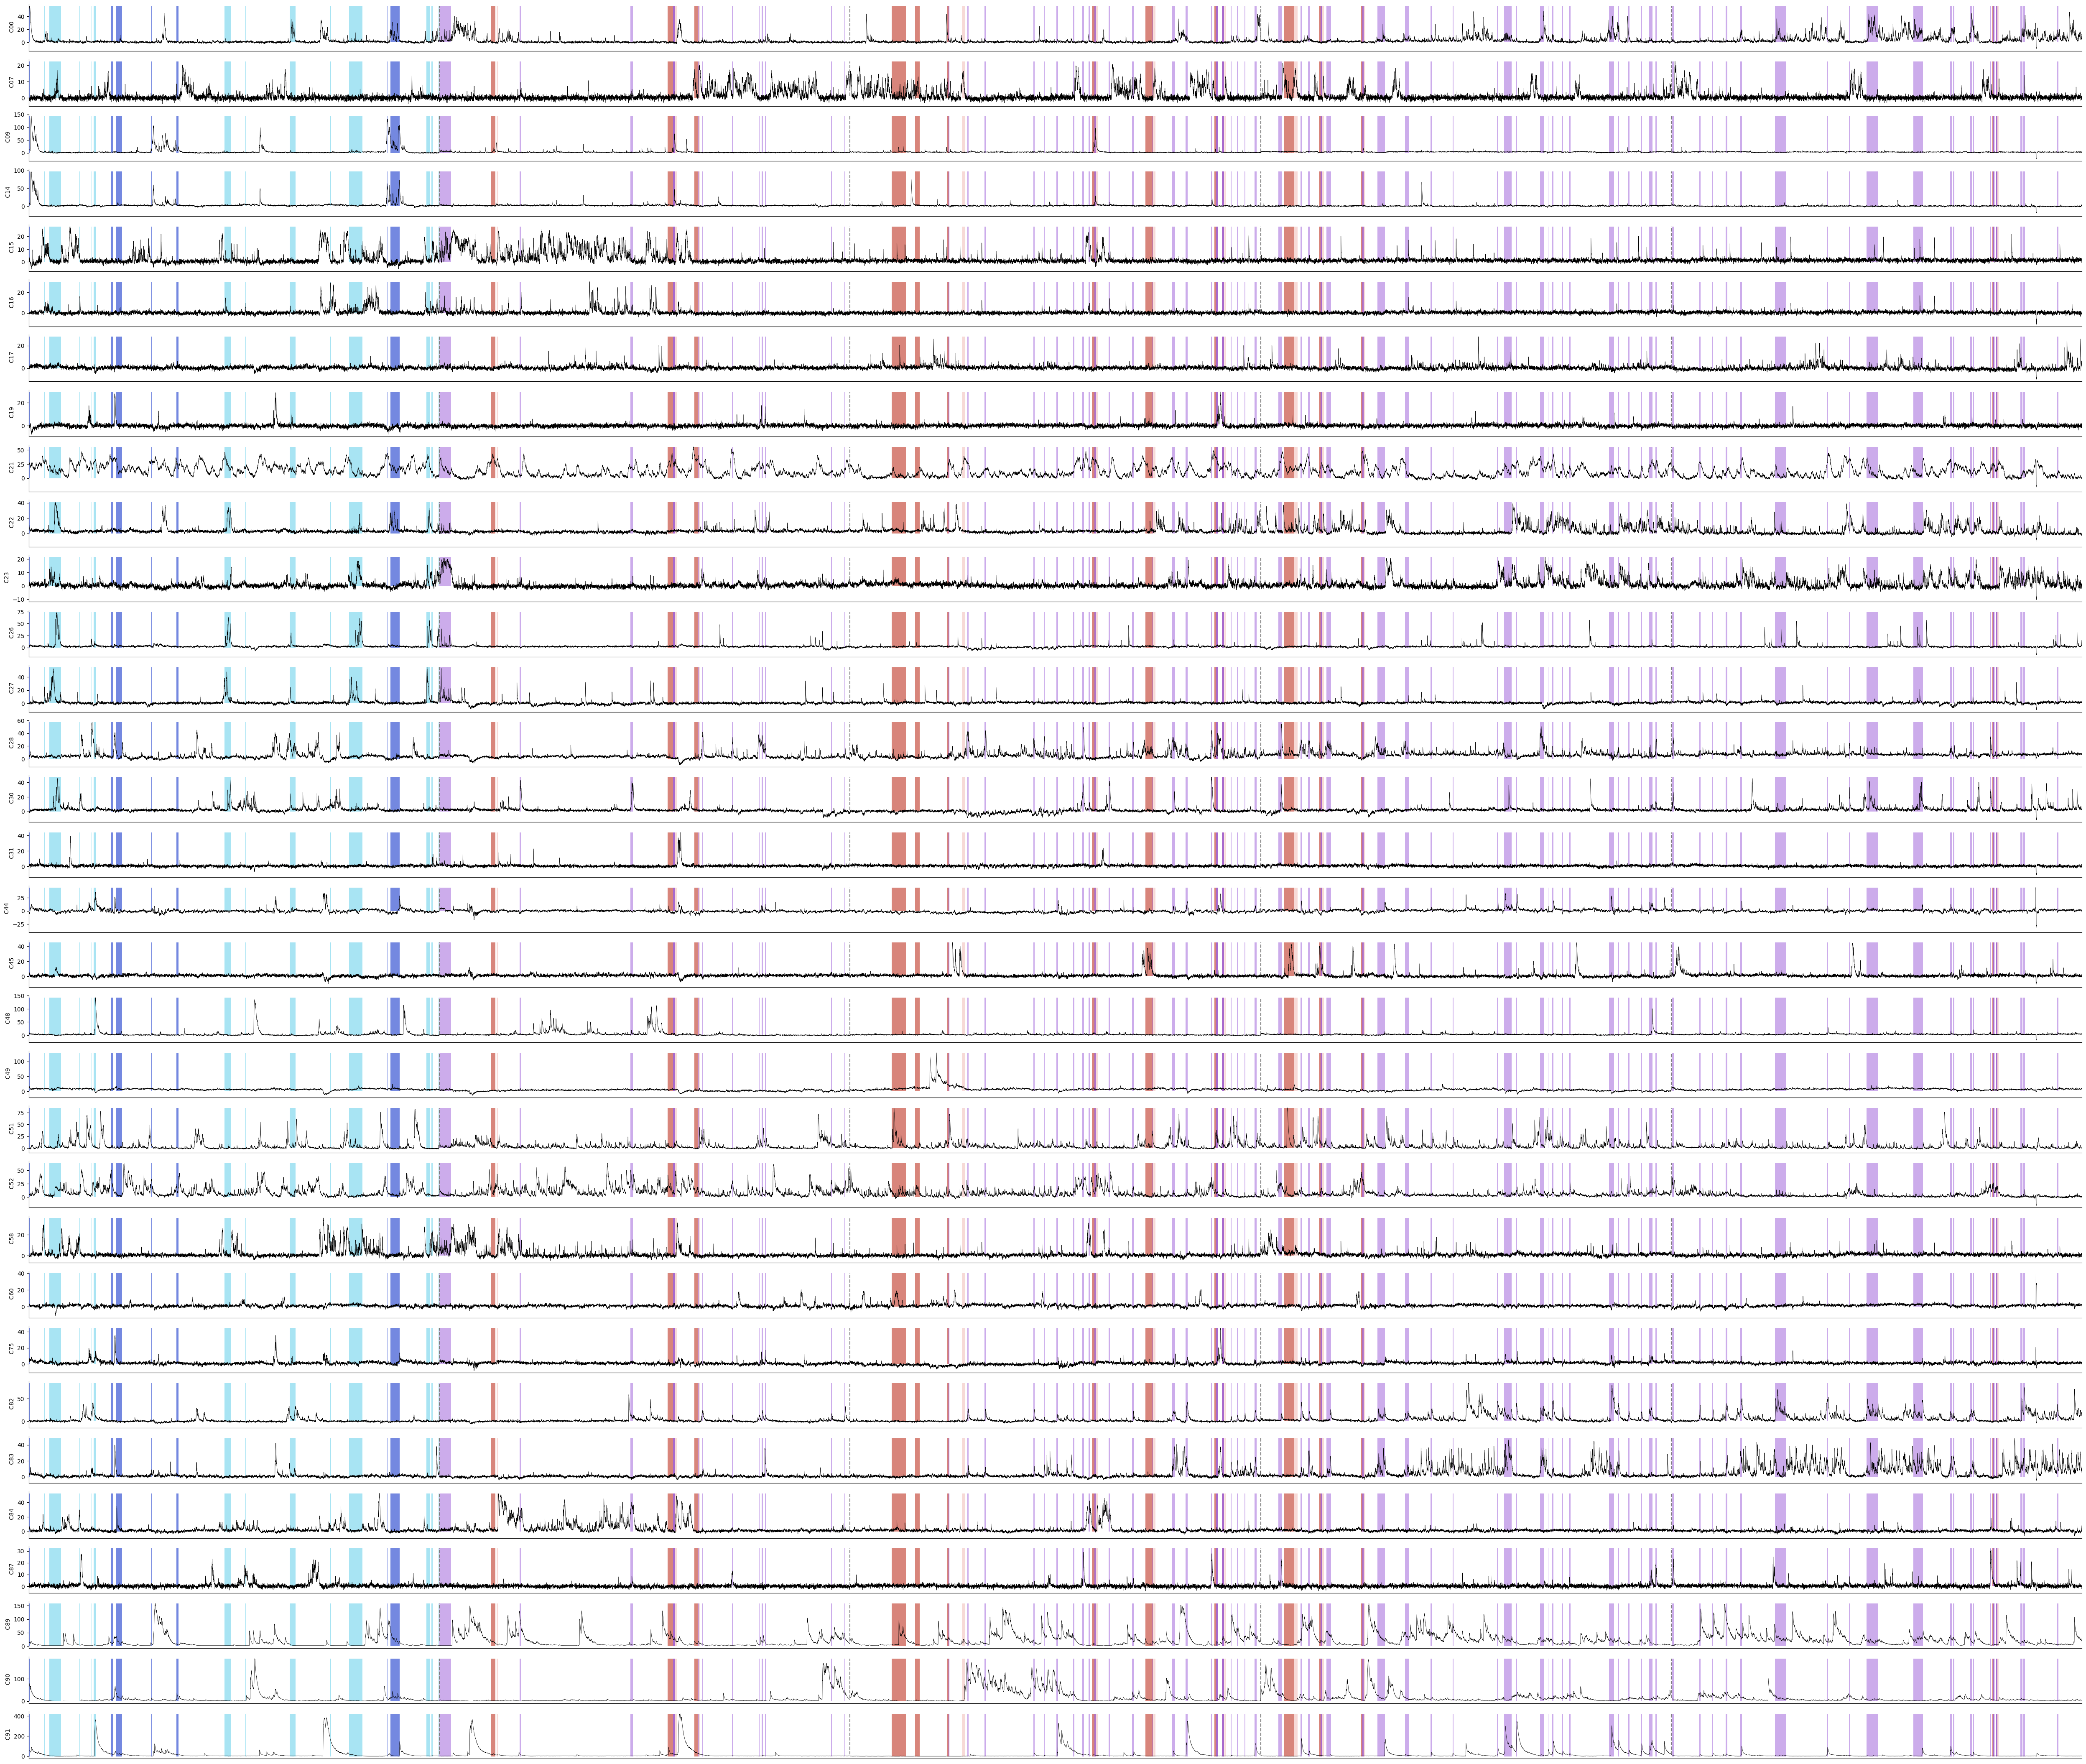

In [22]:
palette = sns.color_palette('viridis',as_cmap=True).colors
# cols = cols_ori[:2] # uncomment this line for full output.
step = int(len(palette)/len(cols))

# UNCOMMENT THIS LINE TO MAKE ALL TRACES BLACK
# palette = ['#000' for i in range(len(palette))]
fig, ax = plt.subplots(len(cols), 1)
fig = plt.gcf()
fig.set_size_inches([50,len(cols)*1.322])

color_indices = [i*step for i in range(len(cols))]
rd.seed(18)
rd.shuffle(color_indices)
#Shuffle colors
# color_indices = [0, 100, 25, 200, 50, 175, 75, 125, 150, 225]
xlim_max = df_data.max()[' ']

# read in files with data <-> class to generate colored blocks for each class
tsvfiles = [f for f in os.listdir('Data') if os.path.isfile('Data/' + f) and '.tsv' in f]
tsvfiles.sort()

for i in range(len(cols)):
    
    max_val = df_data[cols[i]].max()
    min_val = df_data[cols[i]].mean()
    
    for ind,tsv in enumerate(tsvfiles):
        df_sq = pd.read_csv('Data/' + tsv, sep='\t')
        df_sq = df_sq[101:]
        df_sq = df_sq.astype(np.double)
        df_sq['time']-=5.05

        data_x_locations, data_x_colors = generate_squares(df_sq,ind)
        for j,pair in enumerate(data_x_locations):
            ax[i].add_patch(get_rectangle(pair[0],0,pair[1],max_val,data_x_palette[data_x_colors[j]],data_x_colors[j]))
    
   # sns.lineplot(data=df_data,x=" ",y=cols[i],ax=ax[i],color=palette[color_indices[i]],lw=0.8)
    #sns.lineplot(data=df_data,x=" ",y=cols[i],ax=ax[i],color='black',lw=0.5)
    sns_ax = sns.lineplot(data=df_data,x=" ",y=cols[i],ax=ax[i],color='black',lw=0.5)
    #sns.lineplot(data=df_data,x=" ",y=cols[i],ax=ax[i],color=palette[color_indices[i]],lw=0.8)
    sns_ax.set(xticklabels=[]) # remove the tick labels
    sns_ax.set(xlabel=None) # remove the axis label
    sns_ax.tick_params(bottom=False) # remove the ticks  

    for el in segments:
        ax[i].plot([el,el],[min_val,max_val],linestyle='dashed',color='grey')
    
    ax[i].spines['right'].set_visible(False)
    ax[i].spines['top'].set_visible(False)
    ax[i].set_xlim([0,xlim_max])

 
    
fig.tight_layout()
fig.savefig("BlackTraces_ColoredBoxes_All.jpg",dpi=600)
plt.savefig('BlackTraces_ColoredBoxes_All.eps', format='eps',dpi=600)
